# 第八章申请反欺诈模型代码

# 8.1 业务理解

# 8.2 案例：申请反欺诈模型

申请人基础信息表

申请人关系网络数据

8.2.1 异常特征构造

1.异常特征提取的思路

2.构造异常特征

In [1]:
#数据清洗用包
import pandas as pd
from sklearn.preprocessing import StandardScaler #数据标准化
import numpy as np
#建模用包
import sklearn.metrics as metrics
import sklearn.ensemble as ensemble
from sklearn.model_selection import GridSearchCV,train_test_split
#from Mymetrics import *

In [2]:
import pandas as pd

data = pd.read_csv('data/loan1_org_basic.csv')
data.head()

,flag,userid,age,gender,city_level,edu,income
0,0,id100,32,1,2,1,9400
1,0,id10000,31,0,3,2,9400
2,0,id100004,24,1,2,2,7600
3,0,id100013,22,0,2,2,6400
4,0,id100014,24,0,2,2,7600


In [3]:
data.flag.value_counts() 

flag
0    27247
1       74
Name: count, dtype: int64

In [4]:
data.income.describe()

count    27321.000000
mean      8283.638959
std       2107.404906
min       2100.000000
25%       7000.000000
50%       8200.000000
75%      10000.000000
max      17200.000000
Name: income, dtype: float64

# 数据预处理

## 数据转换

对数据进行标准化

In [5]:
from sklearn.preprocessing import StandardScaler
import numpy as np
#对年龄进行中心标准化和其绝对值
data['age_st']=StandardScaler().fit_transform(data[['age']])  
data['age_st_abs']=np.abs(data[['age_st']])  

In [6]:
#对收入进行中心标准化和其绝对值
data['income_st']=StandardScaler().fit_transform(data[['income']])  
data['income_st_abs']=np.abs(data[['income_st']])  

In [7]:
data.income_st.groupby(data.flag).describe() 

,count,mean,std,min,25%,50%,75%,max
flag,,,,,,,,
0,27247.0,0.000202,0.999649,-2.934297,-0.609120,-0.039689,0.814458,4.231045
1,74.0,-0.074316,1.133032,-1.985245,-0.893836,-0.229499,0.529742,2.902372


In [8]:
data.income_st_abs.groupby(data.flag).describe() 

,count,mean,std,min,25%,50%,75%,max
flag,,,,,,,,
0,27247.0,0.799830,0.599622,0.039689,0.324404,0.609120,1.178551,4.231045
1,74.0,0.914448,0.664598,0.087141,0.348131,0.806694,1.273239,2.902372


收入容易被篡改,分析其他与收入有紧密关系的字段,进行回归分析
+ 总体指标否合理
+ 较大残差意味着异常

3.构造交叉验证特征

In [9]:
data.income.describe()

count    27321.000000
mean      8283.638959
std       2107.404906
min       2100.000000
25%       7000.000000
50%       8200.000000
75%      10000.000000
max      17200.000000
Name: income, dtype: float64

<Axes: >

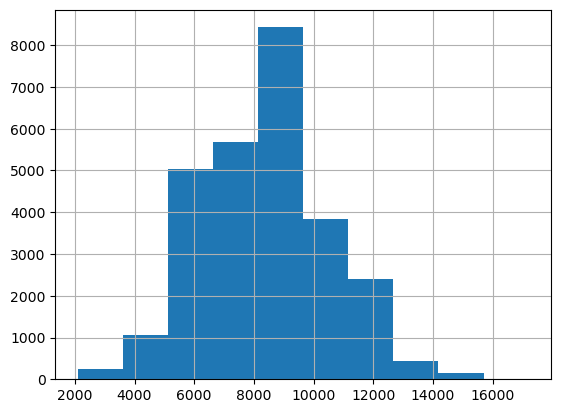

In [10]:
data.income.hist()

In [11]:
import statsmodels.api as sm
from statsmodels.formula.api import ols
lm_m = ols('income ~ age + C(edu) + C(city_level) + C(gender)',data=data).fit()
lm_m.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 income   R-squared:                       0.572
Model:                            OLS   Adj. R-squared:                  0.572
Method:                 Least Squares   F-statistic:                     4061.
Date:                Sun, 25 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:23:13   Log-Likelihood:            -2.3626e+05
No. Observations:               27321   AIC:                         4.725e+05
Df Residuals:                   27311   BIC:                         4.726e+05
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept           1367.2871     73.351     18.640      0.000    1223.516    1511.058
C(edu)[T.2]          454.0774     20.041     22.657      0.000     414.796     493.359
C(edu)[T.3]          715.9856     40.086     17.861      0.000     637.415     794.556
C(edu)[T.4]         1142.1897    104.419     10.939      0.000     937.523    1346.856
C(city_level)[T.2] -2001.3261     39.139    -51.133      0.000   -2078.041   -1924.611
C(city_level)[T.3] -3090.5998     42.847    -72.132      0.000   -3174.581   -3006.618
C(city_level)[T.4] -3674.6817     62.084    -59.189      0.000   -3796.370   -3552.994
C(city_level)[T.5] -3606.9392    167.416    -21.545      0.000   -3935.083   -3278.796
C(gender)[T.1]      -781.0033     19.471    -40.111      0.000    -819.168    -742.839
age                  315.1401      2.338    134.796      0.000     310.558     319.723
==============================================================================
Omnibus:                      419.902   Durbin-Watson:                   2.009
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              310.594
Skew:                           0.166   Prob(JB):                     3.59e-68
Kurtosis:                       2.596   Cond. No.                         575.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

残差即真实值与预测值的差异,本身大小代表了异常程度

In [12]:
data['income_resid'] = lm_m.resid #原始残差
data['income__resid_st']=StandardScaler().fit_transform(data[['income_resid']]) #学生标准化后的残差
data['income__resid_st_abs']=np.abs(data[['income__resid_st']]) #学生标准化后取绝对值的残差

In [13]:
data.income_resid.groupby(data.flag).describe()

,count,mean,std,min,25%,50%,75%,max
flag,,,,,,,,
0,27247.0,-0.569885,1374.868292,-3446.031785,-1046.031785,-9.770491,1010.617093,6725.757237
1,74.0,209.833066,2306.671942,-4195.866064,-1266.838413,-290.778950,1518.650439,6153.968215


In [14]:
data.income__resid_st.groupby(data.flag).describe()

,count,mean,std,min,25%,50%,75%,max
flag,,,,,,,,
0,27247.0,-0.000414,0.997589,-2.500402,-0.758989,-0.007089,0.733293,4.880135
1,74.0,0.152253,1.673696,-3.044474,-0.919204,-0.210986,1.101916,4.465251


## 数据探查

### 单变量分析

In [15]:
import seaborn as sns 
import matplotlib.pyplot as plt 
import pandas as pd
import numpy as np
from matplotlib import rcParams #图片大小
rcParams['figure.figsize'] = (5, 5) #图片精度
rcParams['figure.dpi'] = 100 #线宽
rcParams['lines.linewidth'] = 2 #是否显示网格
rcParams['axes.grid'] = True #axes 填充颜色为浅灰
rcParams['axes.facecolor'] = '#eeeeee' #字体大小为14
rcParams['font.size'] = 14 #边框为无色
rcParams['patch.edgecolor'] = 'none'
plt.rcParams['font.sans-serif']=['simhei'] # 添加中文字体为黑体
plt.rcParams['axes.unicode_minus'] =False

查看欺诈相关特征

In [16]:
data.age_st.groupby(data.flag).describe()

,count,mean,std,min,25%,50%,75%,max
flag,,,,,,,,
0,27247.0,-0.001064,0.999817,-2.209477,-0.826611,0.003108,0.832827,4.151704
1,74.0,0.391805,1.003921,-1.103184,-0.273465,0.279681,0.832827,3.598557


In [17]:
data.age_st_abs.groupby(data.flag).describe()

,count,mean,std,min,25%,50%,75%,max
flag,,,,,,,,
0,27247.0,0.829351,0.558379,0.003108,0.279681,0.826611,1.109400,4.151704
1,74.0,0.808302,0.707932,0.003108,0.279681,0.556254,1.103184,3.598557


In [18]:
data.income_st.groupby(data.flag).describe()

,count,mean,std,min,25%,50%,75%,max
flag,,,,,,,,
0,27247.0,0.000202,0.999649,-2.934297,-0.609120,-0.039689,0.814458,4.231045
1,74.0,-0.074316,1.133032,-1.985245,-0.893836,-0.229499,0.529742,2.902372


In [19]:
data.income_st_abs.groupby(data.flag).describe()

,count,mean,std,min,25%,50%,75%,max
flag,,,,,,,,
0,27247.0,0.799830,0.599622,0.039689,0.324404,0.609120,1.178551,4.231045
1,74.0,0.914448,0.664598,0.087141,0.348131,0.806694,1.273239,2.902372


In [20]:
data.income_resid.groupby(data.flag).describe()

,count,mean,std,min,25%,50%,75%,max
flag,,,,,,,,
0,27247.0,-0.569885,1374.868292,-3446.031785,-1046.031785,-9.770491,1010.617093,6725.757237
1,74.0,209.833066,2306.671942,-4195.866064,-1266.838413,-290.778950,1518.650439,6153.968215


In [21]:
data.income__resid_st.groupby(data.flag).describe()

,count,mean,std,min,25%,50%,75%,max
flag,,,,,,,,
0,27247.0,-0.000414,0.997589,-2.500402,-0.758989,-0.007089,0.733293,4.880135
1,74.0,0.152253,1.673696,-3.044474,-0.919204,-0.210986,1.101916,4.465251


In [22]:
data.income__resid_st_abs.groupby(data.flag).describe()

,count,mean,std,min,25%,50%,75%,max
flag,,,,,,,,
0,27247.0,0.824540,0.561510,0.001462,0.363852,0.753779,1.194342,4.880135
1,74.0,1.311795,1.039412,0.017188,0.507139,0.991299,1.951186,4.465251


箱线图

<Axes: xlabel='flag', ylabel='income_resid'>

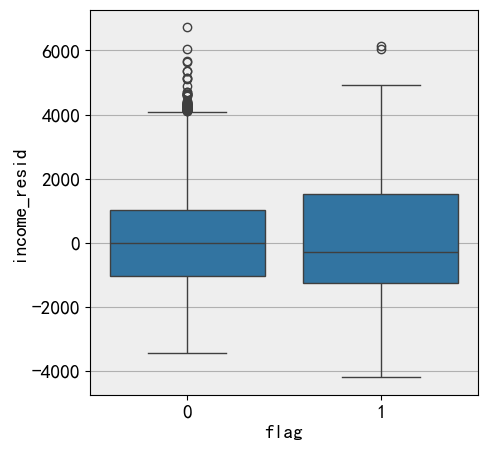

In [23]:
import seaborn as sns 
sns.boxplot(x='flag',y='income_resid',data=data) 

<Axes: xlabel='flag', ylabel='income__resid_st_abs'>

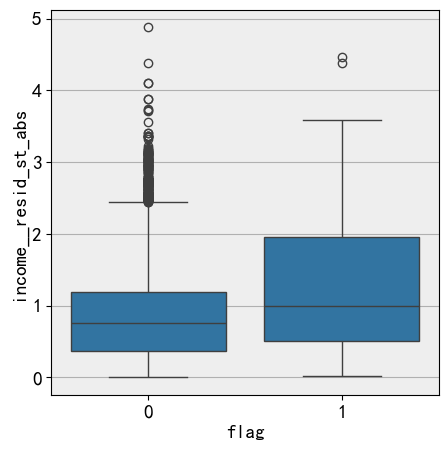

In [24]:
sns.boxplot(x='flag',y='income__resid_st_abs',data=data) 

4.异常特征验证

# 模型构建

## 建模数据准备

第一步：生成建模数据集，并进行数据分区。注意原始数据中欺诈样本量极低，这里只为验证特征所以暂不做处理

In [25]:
import sklearn.ensemble as ensemble
from sklearn.model_selection import GridSearchCV,train_test_split
target = data["flag"]
orgData1 = data.iloc[ :,7:]
train_data, test_data, train_target, test_target = train_test_split(orgData1, target, test_size=0.3, train_size=0.7, random_state=12345)

## 使用GBDT建模

第二步：使用网格搜索与交叉验证得出最优参数的GBDT模型。

In [26]:
param_grid = {
    'loss':['deviance','exponential'],
    'learning_rate':[0.2],
    'n_estimators':[80],  #决策树个数-GBDT特有参数
    'max_depth':[2]  #单棵树最大深度-GBDT特有参数    
} 

In [27]:
gbc = ensemble.GradientBoostingClassifier()
gbccv = GridSearchCV(estimator=gbc, param_grid=param_grid, scoring='roc_auc', cv=4)
gbccv.fit(train_data, train_target)
gbccv.best_params_ #最优参数

D:\keshihua\envs\lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
4 fits failed out of a total of 8.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
4 fits failed with the following error:
Traceback (most recent call last):
  File "D:\keshihua\envs\lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "D:\keshihua\envs\lib\site-packages\sklearn\base.py", line 1358, in wrapper
    estimator._validate_params()
  File "D:\keshihua\envs\lib\site-packages\sklearn\base.py", line 471, in _validate_params
    validate_parameter_constraints(
  File "D:\keshihua\envs\lib\site-packages\sklearn\utils\_param_validation.py", line 9

{'learning_rate': 0.2,
 'loss': 'exponential',
 'max_depth': 2,
 'n_estimators': 80}

## 模型评估

第三步：进行模型评估以验证特征效果。这里主要用到了ROC曲线与PR曲线

In [28]:
import matplotlib.pyplot as plt

def metrics_roc(ts_real_Y, tr_real_Y,ts_pred_prob,tr_pred_prob):
    from sklearn import metrics 
    fpr_test, tpr_test, th_test = metrics.roc_curve(ts_real_Y, ts_pred_prob)
    fpr_train, tpr_train, th_train = metrics.roc_curve(tr_real_Y, tr_pred_prob)
    plt.figure(figsize=[3, 3])
    plt.plot(fpr_test, tpr_test, 'b--')
    plt.plot(fpr_train, tpr_train, 'r-')
    plt.title('ROC curve::Test is Blue')
    print('Test AUC = %.4f' %metrics.auc(fpr_test, tpr_test))
    print('Train AUC = %.4f' %metrics.auc(fpr_train, tpr_train))
    plt.show()

def metrics_pr(ts_real_Y, tr_real_Y,ts_pred_prob,tr_pred_prob):
    from sklearn import metrics 
    precision_test, recall_test, th_test = metrics.precision_recall_curve(ts_real_Y, ts_pred_prob)
    precision_train, recall_train, th_train = metrics.precision_recall_curve(tr_real_Y, tr_pred_prob)
    plt.figure(figsize=[3, 3])
    plt.plot(recall_test,precision_test,  'b--')
    plt.plot(recall_train,precision_train,  'r-')
    plt.title('precision-Recall curve:Test is Blue')
    print('Test AP = %.4f' %metrics.average_precision_score(ts_real_Y, ts_pred_prob))
    print('Train AP = %.4f' %metrics.average_precision_score(tr_real_Y, tr_pred_prob))
    plt.show()

+ 模型评估

In [29]:
train_est = gbccv.predict_proba(train_data)[:,1]
test_est = gbccv.predict_proba(test_data)[:,1]

Test AUC = 0.7752
Train AUC = 0.9735


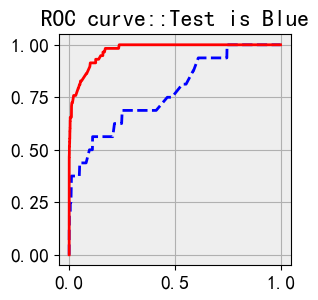

In [30]:
metrics_roc(test_target, train_target,test_est,train_est) 

Test AP = 0.1213
Train AP = 0.5337


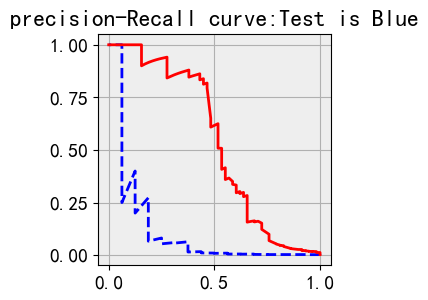

In [31]:
metrics_pr(test_target, train_target,test_est,train_est)

从模型评估结果上看,模型效果欠佳,将考虑使用网络特征构建反欺诈模型

8.2.2 网络特征提取

1.初探欺诈团伙网络

In [32]:
import pandas as pd
dat0=pd.read_csv('data/loan1_org_net.csv')
print(dat0[dat0.userid.eq('id103572') | dat0.connid.eq('id103572')])

         userid    connid  in_date  flag  flag_date
1375   id103572   id77548    42767     1    42779.0
1376   id103572   id33454    42767     1    42779.0
2127   id105351  id103572    42767    -1    42767.0
35165   id62771  id103572    42768     1    42782.0


找到所有与id105351有直接或间接关联的申请人

In [33]:
import numpy as np
#遍历所有与id103572有关系的申请人或联系人
row_index=[]
ids=['id103572']
ids_length=-1;ids_length_new=0 #给定初始值

while ids_length!=ids_length_new: #当更新后找出的有关系的客户编码数量不再变化时停止迭代
    ids_length=len(np.unique(ids)) #每一次迭代的客户编码列表
    row_index.extend(dat0[dat0.userid.isin(ids) | dat0.connid.isin(ids)].index.tolist()) #输出行索引
    ids=dat0[dat0.userid.isin(ids) | dat0.connid.isin(ids)].userid.tolist()+\
            dat0[dat0.userid.isin(ids) | dat0.connid.isin(ids)].connid.tolist() #每一次迭代遍历可能有关联的人
    ids_length_new=len(np.unique(ids)) #更新后的客户编码列表

输出所有与id103572有关系的申请人或联系人

In [34]:
dat0.loc[np.unique(row_index)].count()

userid       33
connid       33
in_date      33
flag         33
flag_date    33
dtype: int64

Python中专门用于构建复杂网络的的networkx库：

第一步：构建这33条关系所组成的网络

In [35]:
import networkx as nx
import numpy as np

# 设置随机种子
np.random.seed(42)

G = nx.Graph()
dat = dat0.loc[np.unique(row_index)]
for i in dat.index:
    s = dat.loc[i, 'userid']
    c = dat.loc[i, 'connid']
    flag = dat.loc[i,'flag']
    in_date = dat.loc[i, 'in_date']
    flag_date = dat.loc[i, 'flag_date']

    G.add_edge(s, c)
    G.nodes[c].setdefault('in_date', in_date)
    G.nodes[s]['flag_date'] = flag_date  
    G.nodes[s].setdefault('in_date', in_date)
    G.nodes[s].setdefault('flag', flag)

第二步则把关系图画出来

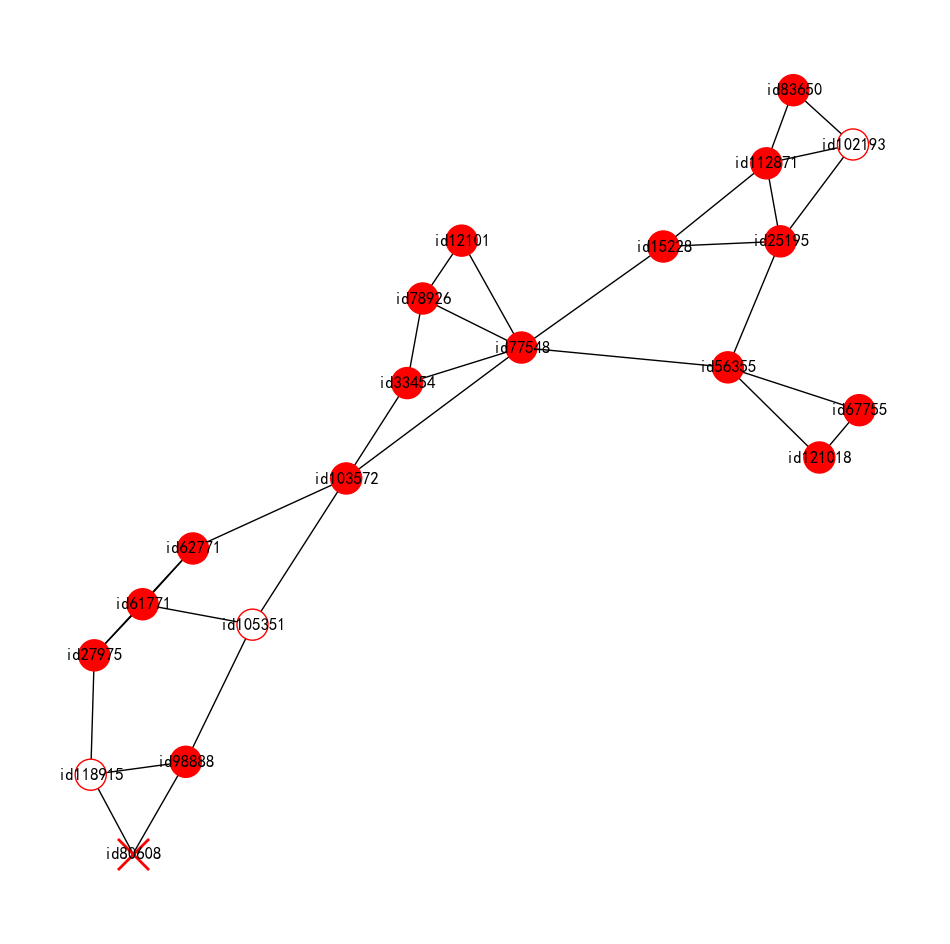

In [36]:
import matplotlib.pyplot as plt 
# 获取所有节点和它们的标志
node_list = list(G.nodes())
flags = [G.nodes[i].get('flag') for i in node_list]

def draw_func():
    # 映射颜色和标记
    node_colors = []
    node_shapes = []
    edge_colors = []  # 边框颜色
    face_colors = []  # 填充颜色

    for flag in flags:
        if flag == 0:  # 正常
            edge_colors.append('green')
            face_colors.append('green')
            node_shapes.append('o')
        elif flag == 1:  # 欺诈
            edge_colors.append('red')
            face_colors.append('red')
            node_shapes.append('o')
        elif flag == -1:  # 拒绝（空心红圈）
            edge_colors.append('red')
            face_colors.append('white')
            node_shapes.append('o')
        elif flag == -2:  # 违约
            edge_colors.append('purple')
            face_colors.append('purple')
            node_shapes.append('o')
        else:  # 待定
            edge_colors.append('red')
            face_colors.append('red')
            node_shapes.append('x')
  
    # 获取布局
    pos = nx.spring_layout(G)
  
    # 分别绘制圆形节点和X形节点
    circle_nodes = [node for i, node in enumerate(node_list) if node_shapes[i] == 'o']
    x_nodes = [node for i, node in enumerate(node_list) if node_shapes[i] == 'x']

    circle_edge_colors = [color for i, color in enumerate(edge_colors) if node_shapes[i] == 'o']
    circle_face_colors = [color for i, color in enumerate(face_colors) if node_shapes[i] == 'o']
    x_colors = [color for i, color in enumerate(edge_colors) if node_shapes[i] == 'x']
  
    # 绘制网络图
    plt.figure(figsize=(12, 12))
  
    # 绘制边
    nx.draw_networkx_edges(G, pos)
  
    # 绘制圆形节点
    nx.draw_networkx_nodes(G, pos,
                      nodelist=circle_nodes,
                      edgecolors=circle_edge_colors,  # 设置边框颜色
                      node_color=circle_face_colors,  # 设置填充颜色
                      node_shape='o',
                      node_size=500)
  
    # 绘制X形节点
    nx.draw_networkx_nodes(G, pos,
                      nodelist=x_nodes,
                      node_color=x_colors,
                      node_shape='x',
                      node_size=500)

    # 绘制标签
    nx.draw_networkx_labels(G, pos)

    plt.axis('off')
    plt.show()

draw_func()

2.图分割与社团发现

In [37]:
G = nx.Graph()
dat=dat0
for i in dat.index:
    s = dat.loc[i, 'userid'] #客户号
    c = dat.loc[i, 'connid'] #联系人
    flag = dat.loc[i,'flag'] #好坏标签
    in_date = dat.loc[i, 'in_date'] #加入网络时间
    flag_date = dat.loc[i, 'flag_date'] #事件发生时间

    G.add_edge(s, c) #添加节点与边
    G.nodes[c].setdefault('in_date', in_date) 
    G.nodes[s]['flag_date'] = flag_date
    G.nodes[s].setdefault('in_date', in_date)
G.nodes[s].setdefault('flag', flag)

print (len(G.nodes)) #节点数量
print (len(G.edges)) #边数量

87607
48464


louvain算法

In [38]:
#首先使用pip install python-louvain安装算法库
import community.community_louvain
partition = community.community_louvain.best_partition(G)

子图规模初步统计

In [39]:
partition_s=pd.Series(partition)
partition_s.value_counts(sort=False) #所有子图的规模统计

0        2
1        3
2        2
3        2
4        2
        ..
39178    2
39179    2
39180    2
39181    2
1127     2
Name: count, Length: 39182, dtype: int64

联通子图法

In [40]:
G = nx.Graph()
dat=dat0 #假定在时点42781建立了关系网络
for i in dat.index:
    s = dat.loc[i, 'userid'] #客户号
    c = dat.loc[i, 'connid'] #联系人
    flag = dat.loc[i,'flag'] #好坏标签
    in_date = dat.loc[i, 'in_date'] #加入网络时间
    flag_date = dat.loc[i, 'flag_date'] #事件发生时间

    G.add_edge(s, c) #添加节点与边
    G.nodes[c].setdefault('in_date', in_date) 
    G.nodes[s]['flag_date'] = flag_date
    G.nodes[s].setdefault('in_date', in_date)
    G.nodes[s].setdefault('flag', flag)
    
con_comps=nx.connected_components(G)

In [41]:
count=1
se=pd.Series(dtype='float64')
for comp in con_comps:
    se=pd.concat([pd.Series(count,index=list(comp)),se])
    count=count+1

C:\Users\15587\AppData\Local\Temp\ipykernel_44512\1328322409.py:4: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  se=pd.concat([pd.Series(count,index=list(comp)),se])


以louvain算法结果为例，找到欺诈者的子网络形态

In [42]:
import community.community_louvain
partition = community.community_louvain.best_partition(G)
partition_s=pd.Series(partition)
#寻找所有欺诈者所在的社团编号
dat=dat0
fgroup=dat[dat.flag.isin([1])][['userid']].drop_duplicates().set_index('userid').join(partition_s.rename('group'))
fgroup.group.unique() #所有欺诈者所在的社团编号

array([  675,  1286,  2194,  2976,  4085,  4090,  5234,  5602,  7077,
        7098,  7764,  8209,  8615,  8858, 10662, 11085, 11447, 12373,
       12394, 13752, 14930, 15095, 16955, 17178, 17672, 19838, 20130,
       21130, 21210, 21921, 23425, 23841, 23931, 24347, 24639, 24725,
       24961, 25849, 25867, 26400, 26713, 27975, 29507, 30807, 31044,
       31732, 31934, 32565, 35538, 35550, 37861, 37945, 38158, 38733,
       39032])

对这些包含欺诈者的网络进行网络规模统计

In [43]:
partition_s[partition_s.isin(fgroup.group.unique())].value_counts().sort_values().tail()

19838     3
31934     3
4090      3
11447     3
675      20
Name: count, dtype: int64

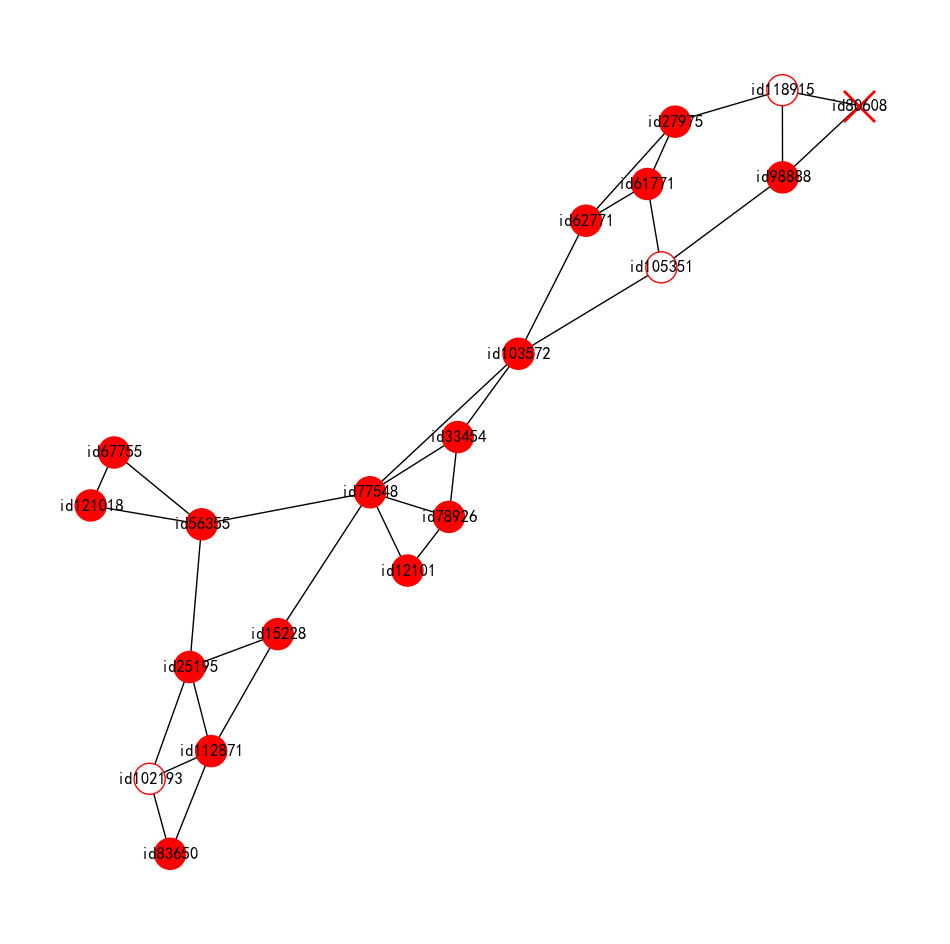

In [44]:
G = nx.Graph()
dat=dat0
dat=dat[dat.userid.isin(partition_s[partition_s==675].index) | dat.connid.isin(partition_s[partition_s==675].index)]
for i in dat.index:
    s = dat.loc[i, 'userid'] #客户号
    c = dat.loc[i, 'connid'] #联系人
    flag = dat.loc[i,'flag'] #好坏标签
    in_date = dat.loc[i, 'in_date'] #加入网络时间
    flag_date = dat.loc[i, 'flag_date'] #事件发生时间

    G.add_edge(s, c) #添加节点与边
    G.nodes[c].setdefault('in_date', in_date) 
    G.nodes[s]['flag_date'] = flag_date
    G.nodes[s].setdefault('in_date', in_date)
    G.nodes[s].setdefault('flag', flag)


draw_func()

编号10500的子网络

id133498 {'flag_date': np.float64(nan), 'in_date': np.int64(42761), 'flag': np.int64(0)}
id134089 {'in_date': np.int64(42761)}
id22710 {'in_date': np.int64(42761)}
id27951 {'flag_date': np.float64(nan), 'in_date': np.int64(42777), 'flag': np.int64(0)}
id33913 {'in_date': np.int64(42777)}
id52071 {'flag_date': np.float64(nan), 'in_date': np.int64(42794), 'flag': np.int64(0)}
id128082 {'in_date': np.int64(42794)}
id55572 {'flag_date': np.float64(nan), 'in_date': np.int64(42766), 'flag': np.int64(0)}
id34114 {'in_date': np.int64(42766)}
id60706 {'flag_date': np.float64(nan), 'in_date': np.int64(42806), 'flag': np.int64(0)}
id68776 {'in_date': np.int64(42806)}
id7653 {'flag_date': np.float64(nan), 'in_date': np.int64(42763), 'flag': np.int64(0)}
id5619 {'in_date': np.int64(42763)}
id91356 {'flag_date': np.float64(nan), 'in_date': np.int64(42794), 'flag': np.int64(0)}
id6074 {'in_date': np.int64(42794)}


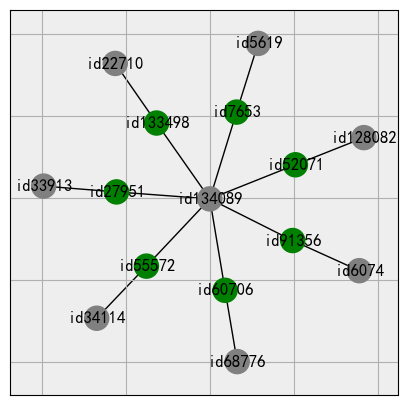

In [45]:
G = nx.Graph()
dat=dat0
dat=dat[dat.userid.isin(partition_s[partition_s==10500].index) | dat.connid.isin(partition_s[partition_s==10500].index)]
for i in dat.index:
    s = dat.loc[i, 'userid'] #客户号
    c = dat.loc[i, 'connid'] #联系人
    flag = dat.loc[i,'flag'] #好坏标签
    in_date = dat.loc[i, 'in_date'] #加入网络时间
    flag_date = dat.loc[i, 'flag_date'] #事件发生时间

    G.add_edge(s, c) #添加节点与边
    G.nodes[c].setdefault('in_date', in_date) 
    G.nodes[s]['flag_date'] = flag_date
    G.nodes[s].setdefault('in_date', in_date)
    G.nodes[s].setdefault('flag', flag)
    
for i in G.nodes:
    print(i,G.nodes[i]) 

def mapcolor(flags):
    l=[]
    for i in flags:
        if i==0:#正常
            l.append('green')
        elif i==1:#欺诈
            l.append('red')
        elif i==-1:#拒绝
            l.append('orange')    
        elif i==-2:#违约
            l.append('purple')
        else: #待定
            l.append('grey')
    return l    
    

nx.draw_networkx(G,node_size=300,font_color='black',node_color=mapcolor([G.nodes[i].get('flag') for i in G.nodes]))

攻击的第一天发生在42467时间点，构建42467时间点前的子网络数据

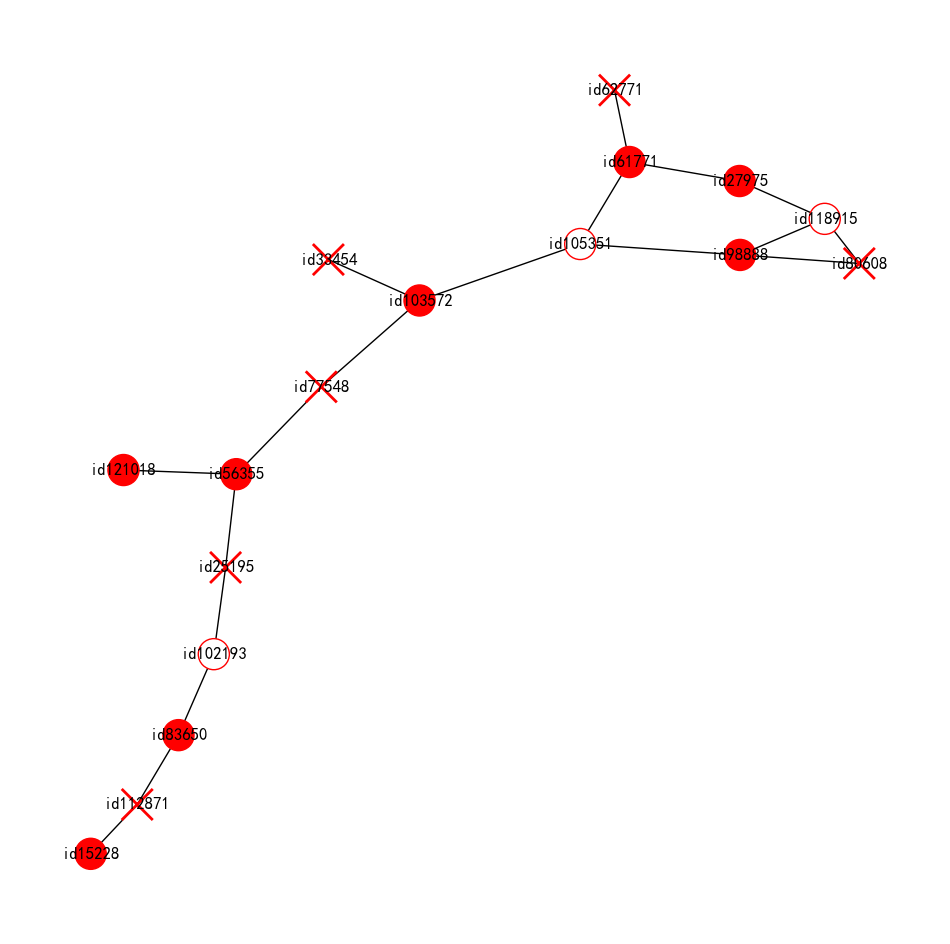

In [46]:
# 第一天
G = nx.Graph()
dat1=dat0[dat0.userid.isin(partition_s[partition_s==675].index) | dat0.connid.isin(partition_s[partition_s==675].index)]
dat=dat1[dat1.in_date.le(42767)]
for i in dat.index:
    s = dat.loc[i, 'userid'] #客户号
    c = dat.loc[i, 'connid'] #联系人
    flag = dat.loc[i,'flag'] #好坏标签
    in_date = dat.loc[i, 'in_date'] #加入网络时间
    flag_date = dat.loc[i, 'flag_date'] #事件发生时间

    G.add_edge(s, c) #添加节点与边
    G.nodes[c].setdefault('in_date', in_date) 
    G.nodes[s]['flag_date'] = flag_date
    G.nodes[s].setdefault('in_date', in_date)
    G.nodes[s].setdefault('flag', flag)
    
node_list = list(G.nodes())
flags = [G.nodes[i].get('flag') for i in node_list]
draw_func()

第二天的网络

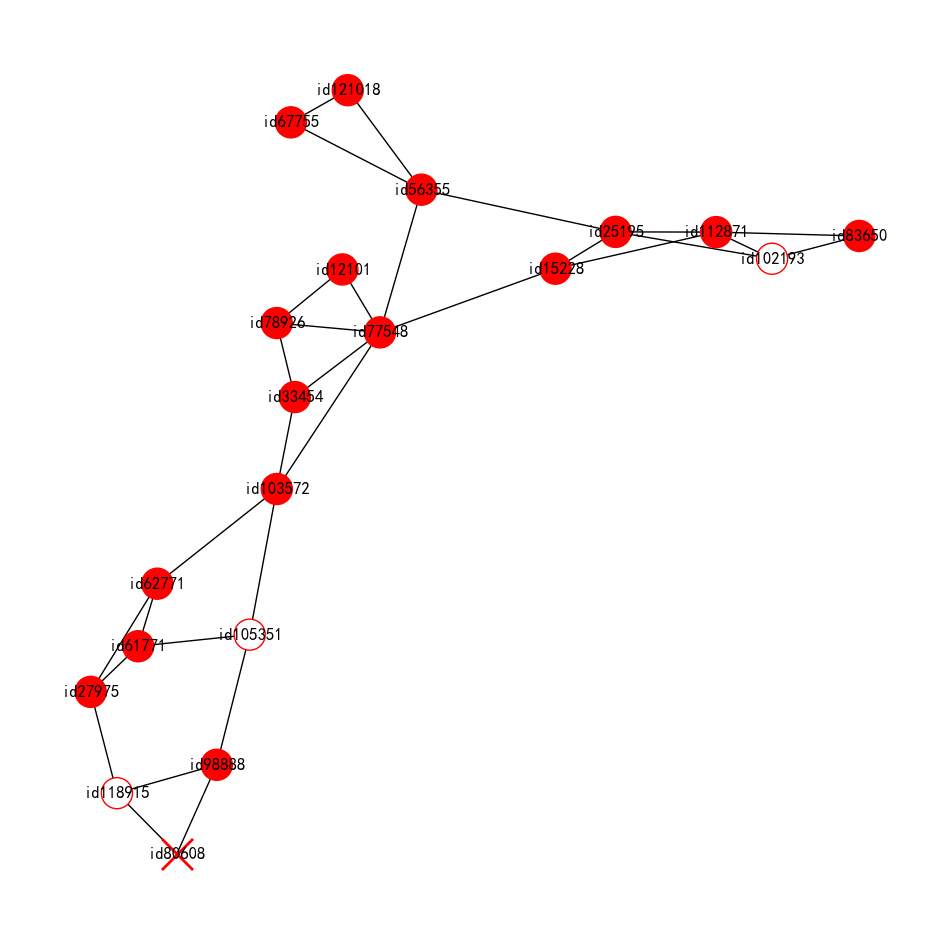

In [47]:
#第二天
G = nx.Graph()
dat1=dat0[dat0.userid.isin(partition_s[partition_s==675].index) | dat0.connid.isin(partition_s[partition_s==675].index)]
dat=dat1[dat1.in_date.le(42768)]
for i in dat.index:
    s = dat.loc[i, 'userid'] #客户号
    c = dat.loc[i, 'connid'] #联系人
    flag = dat.loc[i,'flag'] #好坏标签
    in_date = dat.loc[i, 'in_date'] #加入网络时间
    flag_date = dat.loc[i, 'flag_date'] #事件发生时间

    G.add_edge(s, c) #添加节点与边
    G.nodes[c].setdefault('in_date', in_date) 
    G.nodes[s]['flag_date'] = flag_date
    G.nodes[s].setdefault('in_date', in_date)
    G.nodes[s].setdefault('flag', flag)

node_list = list(G.nodes())
flags = [G.nodes[i].get('flag') for i in node_list]

# 绘制网络图
draw_func()

3.构造异常网络特征

In [48]:
def create_graph(G, data):
    '''更新图：在当前时刻之前图G基础上，添加当前时刻的子网络'''
    for i in data.index:
        s = data.loc[i, 'userid'] #客户号
        c = data.loc[i, 'connid'] #联系人
        flag = data.loc[i,'flag'] #好坏标签
        in_date = data.loc[i, 'in_date'] #加入网络时间
        flag_date = data.loc[i, 'flag_date'] #事件发生时间

        G.add_edge(s, c) #添加节点与边
        G.nodes[c].setdefault('in_date', in_date) 
        G.nodes[s]['flag_date'] = flag_date
        G.nodes[s].setdefault('in_date', in_date)
        G.nodes[s].setdefault('flag', flag)

    return G

def get_net_info(G, data):
    '''
        计算图中节点信息：计算当天图中新增节点的信息
        G: 截止到当前时刻的图
        data: 当前时刻的数据
    '''
    result = pd.DataFrame(index=data.index)#获取当前时刻数据的索引，便于添加列操作

    net_size = {k: len(nx.node_connected_component(G, k)) for k in data.userid.values}#当天新增客户所在联通图的大小
    degree = G.degree([*data.userid.values])#当天新增客户在网络中的度
    average_neighbor_degree = nx.average_neighbor_degree(G, nodes=[*data.userid.values])#当天新增客户所在联通图中与之链接节点的平均度
    #degree_centrality = {k: nx.degree_centrality(G)[k] for k in data.userid.values}#点度中心度
    #closeness_centrality = {k: nx.closeness_centrality(G)[k] for k in data.userid.values}#距中心距离，当天新增客户距离网络中心的距离（耗时较长）
    #betweenness_centrality = {k: nx.betweenness_centrality(G)[k] for k in data.userid.values}#介度中心度
    percentage = {k: get_percentage(G, k) for k in data.userid.values}#当天新增客户所在联通图中之前客户的逾期情况

    result["net_size"] = data.userid.map(net_size)
    result["degree"] = data.userid.map(degree)
    result["average_neighbor_degree"] = data.userid.map(average_neighbor_degree)
    #result["degree_centrality"] = data.userid.map(degree_centrality)
    #result["closeness_centrality"] = data.userid.map(closeness_centrality)
    #result["betweenness_centrality"] = data.userid.map(betweenness_centrality)
    result["percentage"] = data.userid.map(percentage)
    
    return result

def get_percentage(G, x):
    """
    计算节点所在联通网络的坏客户比例
    G-当前时刻的图
    x-该节点的ID号，字符变量
    """
    flags = []
    for i in nx.node_connected_component(G, x):
        # 获取flag_date的时间
        cond = G.nodes[i].get('flag_date', 9999999999) #默认9999999999
        flag = G.nodes[i].get('flag', 0) #默认0
        # 判断条件：cond小于等于 x的in_date
        
        if cond <G.nodes[x]["in_date"]:
            if flag == 1 or flag==-1 or flag==-2:
                mark = 1
            else:
                mark = 0
        elif cond == G.nodes[x]["in_date"]:
            if flag==-1:
                mark = 1
            else:
                mark = 0
        else:
            mark = 0
        flags.append(mark)
    return np.mean(flags)

通过循环模拟每天更新网络，计算剩余特征，保存特征的过程

In [49]:
G = nx.Graph()
analysis = pd.DataFrame() 
connid = pd.Series()
dates = dat.in_date.drop_duplicates()
dateList = dates.tolist()
dateList.sort() #根据时间进行排序

for date in dateList:
    # 获取每天的数据
    dayData = dat.loc[dat.in_date == date]
    # 创建截至当天的图
    G = create_graph(G, dayData)
    res = get_net_info(G, dayData) 
    res['date'] = date #更新时间戳
    res['flag'] = dayData.flag #欺诈标签
    res['flag_date'] = dayData.flag_date #事件发生日期
    res['userid'] = dayData.userid #客户ID
    res['is_AC'] = dayData.userid.isin(connid).astype('int') #客户是否由联系人转化
    analysis = pd.concat([analysis, res]) #历史分析数据
connid = pd.concat([connid,dayData.connid]) #历史联系人列表

analysis = analysis[analysis.flag !=-2]#剔除违约客户
analysis = analysis[analysis.flag !=-1]#剔除拒绝客户  
analysis = analysis.drop_duplicates()
analysis = analysis.merge(analysis.groupby('userid').date.max().reset_index(),on=['userid','date'],how='inner')
analysis.drop(['date','flag_date'],axis=1).to_csv('data/loan2_analysis_net.csv')    #20250503 将“1”改为“axis=1” 3.12与3.8的差异所致

8.2.3 构建识别模型

1.合并数据

In [50]:
import pandas as pd
from sklearn.model_selection import GridSearchCV,train_test_split
import sklearn.ensemble as ensemble
df1 = pd.read_csv('data/loan2_analysis_basic.csv') #异常特征
df2 = pd.read_csv('data/loan2_analysis_net.csv')
df=df1[['userid','flag','gender','city_level','edu','age_st','income_st','income__resid_st','income__resid_st_abs']].merge(
df2[['userid','net_size','degree','average_neighbor_degree','percentage']],on='userid',how='left'
)

这里暂不做样本平衡处理，在模型选择上，使用sklearn的GBDT模型训练，目的在于对比异常特征模型

Test AUC = 0.7320
Train AUC = 0.8160


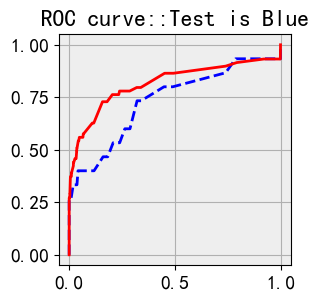

In [57]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import metrics
from sklearn import ensemble
from sklearn.model_selection import train_test_split, GridSearchCV

def metrics_roc(ts_real_Y, tr_real_Y, ts_pred_prob, tr_pred_prob):
    fpr_test, tpr_test, th_test = metrics.roc_curve(ts_real_Y, ts_pred_prob)
    fpr_train, tpr_train, th_train = metrics.roc_curve(tr_real_Y, tr_pred_prob)
    plt.figure(figsize=[3, 3])
    plt.plot(fpr_test, tpr_test, 'b--')
    plt.plot(fpr_train, tpr_train, 'r-')
    plt.title('ROC curve::Test is Blue')
    print('Test AUC = %.4f' % metrics.auc(fpr_test, tpr_test))
    print('Train AUC = %.4f' % metrics.auc(fpr_train, tpr_train))
    plt.show()

def metrics_pr(ts_real_Y, tr_real_Y, ts_pred_prob, tr_pred_prob):
    precision_test, recall_test, th_test = metrics.precision_recall_curve(ts_real_Y, ts_pred_prob)
    precision_train, recall_train, th_train = metrics.precision_recall_curve(tr_real_Y, tr_pred_prob)
    plt.figure(figsize=[3, 3])
    plt.plot(recall_test, precision_test, 'b--')
    plt.plot(recall_train, precision_train, 'r-')
    plt.title('precision-Recall curve:Test is Blue')
    print('Test AP = %.4f' % metrics.average_precision_score(ts_real_Y, ts_pred_prob))
    print('Train AP = %.4f' % metrics.average_precision_score(tr_real_Y, tr_pred_prob))
    plt.show()

# 假设 df 已经在之前的代码中定义
target = df["flag"]
orgData1 = df.drop('flag', axis=1).set_index('userid')

train_data, test_data, train_target, test_target = train_test_split(
    orgData1, target, test_size=0.3, train_size=0.7, random_state=12345
)  

param_grid = {
    'loss': ['log_loss', 'exponential'], 
    'learning_rate': [0.1, 0.3],
    'n_estimators': [35],         
    'max_depth': [1, 2],          
    'min_samples_split': [2, 4] 
}

# 处理空值
train_data = train_data.fillna(0)
train_target = train_target.fillna(0)
test_data = test_data.fillna(0)
test_target = test_target.fillna(0)

gbc = ensemble.GradientBoostingClassifier()
gbccv = GridSearchCV(estimator=gbc, param_grid=param_grid, scoring='f1', cv=4)
gbccv.fit(train_data, train_target)

train_est = gbccv.predict_proba(train_data)[:, 1]
test_est = gbccv.predict_proba(test_data)[:, 1]

metrics_roc(test_target, train_target, test_est, train_est)

Test AP = 0.3387
Train AP = 0.4214


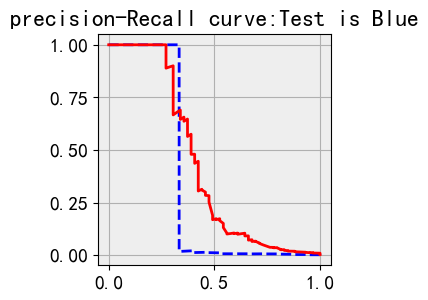

In [52]:
metrics_pr(test_target, train_target,test_est,train_est)

2.样本平衡

In [55]:
df1 = pd.read_csv('data/loan2_analysis_basic.csv')
df2 = pd.read_csv('data/loan2_analysis_net.csv')
df=df1[['userid','flag','gender','city_level','edu','age_st','income_st','income__resid_st','income__resid_st_abs']].merge(
    df2[['userid','net_size','degree','average_neighbor_degree','percentage']],on='userid',how='left'
)
df.head()

target = df["flag"]
orgData1 =df.drop('flag',axis=1).set_index('userid') #20250503 将“1”改为“axis=1” 3.12与3.8的差异所致

from sklearn.preprocessing import scale
orgData2=orgData1.apply(scale)

train_data, test_data, train_target, test_target = train_test_split(
    orgData2, target, test_size=0.3, train_size=0.7, random_state=12345)

（1）随机过抽样

In [59]:
from imblearn.over_sampling import RandomOverSampler
random = RandomOverSampler(sampling_strategy=0.2,random_state=0)
train_data_1, train_target_1 = random.fit_resample(train_data, train_target)

（2）SMOTE

In [60]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(sampling_strategy=0.2,random_state=0)
#增加空值处理
train_data=train_data.fillna(0)
train_target=train_target.fillna(0)

train_data_2, train_target_2 = smote.fit_resample(train_data, train_target)

（3）SMOTE-BorderLine

In [61]:
from imblearn.over_sampling import BorderlineSMOTE
smote_borderline = BorderlineSMOTE(sampling_strategy=0.2,random_state=0)
train_data_3, train_target_3 = smote_borderline.fit_resample(train_data, train_target)

（4）SMOTE-Tomek

In [62]:
from imblearn.combine import SMOTETomek
smote_tomek = SMOTETomek(sampling_strategy=0.2,random_state=0)
train_data_4, train_target_4 = smote_tomek.fit_resample(train_data, train_target)

（5）SMOTE-ENN

In [63]:
from imblearn.combine import SMOTEENN
smote_enn = SMOTEENN(sampling_strategy=0.2,random_state=0)
train_data_5, train_target_5 = smote_enn.fit_resample(train_data, train_target)

3.最优模型

（1）贝叶斯参数优化的LightGBM模型

In [68]:
#pip install bayesian-optimization 20250503提前安装bayesian-optimization 虚机pip install bayesian-optimization -i https://mirrors.aliyun.com/pypi/simple/
from lightgbm import LGBMClassifier
from bayes_opt import BayesianOptimization
def BayesianOptimizationLGB(para_space,data,n_iter,init_points):
    """
    LGB贝叶斯调参：
        LGB_CV:LGB_CV函数,使用auc作为优化标准，5折交叉验证
        para_space:参数空间
        n_iter:贝叶斯优化迭代次数,次数越大越容易找到最优参数,但会更耗时间 
        init_points:随机探索次数,次数越多越有助于差异化参数探索空间，从而避免局部优化
    """ 

    #寻优   
    def LGB_CV(n_estimators,learning_rate,max_depth,min_split_gain,min_sum_hessian_in_leaf,subsample,colsample_bytree,reg_lambda):
        
        AUCbest=0.5
        ITERbest=0
            
        paramt = {
                      'boosting_type' : ['gbdt'],
                      'n_estimators':[int(n_estimators)],
                      'learning_rate':[learning_rate],          
                      'max_depth' : [int(max_depth)],
                      'min_split_gain':[min_split_gain],
                      'min_sum_hessian_in_leaf' : [min_sum_hessian_in_leaf],           
                      'subsample' : [max(min(subsample, 1), 0)],
                      'colsample_bytree' : [max(min(colsample_bytree, 1), 0)],
                      'reg_lambda' : [reg_lambda]
                      }
        
        girdres=GridSearchCV(LGBMClassifier(seed=123),paramt,cv=5,scoring='roc_auc',error_score=0).fit(data['X_train'],data['y_train'])#categorical_feature=['xxx']
        
        val_score = girdres.cv_results_['mean_test_score'][0] #交叉验证集的平均结果
        print(' Stopped after %d iterations with val-score = %f' % (n_estimators,val_score))
        return(val_score)          
    
    Optimize = BayesianOptimization(LGB_CV,para_space)
    Optimize.maximize(n_iter=n_iter,init_points=init_points)
    
    #输出最优参数并重新建模
    params_best=Optimize.max['params']
    params_best['max_depth']=int(params_best['max_depth'])
    params_best['n_estimators']=int(params_best['n_estimators'])
    
    lgb_best = LGBMClassifier(
        colsample_bytree=params_best['colsample_bytree'],
        min_split_gain=params_best['min_split_gain'],
        min_sum_hessian_in_leaf=params_best['min_sum_hessian_in_leaf'],
        learning_rate=params_best['learning_rate'],          
        max_depth=params_best['max_depth'],
        n_estimators=params_best['n_estimators'],
        reg_lambda=params_best['reg_lambda'],
        subsample=params_best['subsample']
    ).fit(data['X_train'],data['y_train'])#categorical_feature=['xxx']
    train_pred = lgb_best.predict_proba(data['X_train'])[:,1]
    test_pred = lgb_best.predict_proba(data['X_test'])[:,1]
    
    train_auc=metrics.roc_auc_score(data['y_train'],train_pred)
    test_auc=metrics.roc_auc_score(data['y_test'],test_pred)
    
    print('auc_train:{},auc_cv:{},auc_test:{}'.format(round(train_auc,4),
                                                      round(Optimize.max['target'],4),
                                                      round(test_auc,4)))
    ParaDf_all=pd.DataFrame()
    
    for i in range(len(Optimize.res)):
        ParaDf=pd.DataFrame([Optimize.res[i]['params']])
        ParaDf['cv_auc']=Optimize.res[i]['target']    
        
        ParaDf_all=pd.concat([ParaDf,ParaDf_all],ignore_index=True) 
    
    return(lgb_best,ParaDf_all,Optimize)

定义训练模型函数

In [69]:
def trainLGB(data):
    
    #这里定义参数搜索范围
    para_space={
            'n_estimators':(10,120),
            'learning_rate':(0.05,0.2), #学习率
            'max_depth':(1,3),#[0,∞],一般3-10，单棵树最大深度，数值越高过拟合程度越高，反之则越低
            'min_split_gain': (0,10),#gama值[0,∞]，i/10.0 for i in range(0,5) 决定树进一步生长的最小损失限制，数值越大，树生长难度越大，过拟合程度越低
            'min_sum_hessian_in_leaf': (0,10),#[0,∞] 最小叶节点二阶梯度和限制,损失函数为MSE时即为最小叶节点样本量限制
            'subsample': (0.5,1),#(0,1],np.logspace(-0.3,0,10),即0.5-1 每一次提升过程中随机样本比例，小于1将避免过度拟合
            'colsample_bytree' :(0.5,1),#(0,1],np.logspace(-0.3,0,10),即0.5-1 每一次提升过程中随机特征比例，小于1将避免过度拟合
            'reg_lambda':(0,1) #正则项权重，默认0，
           }
    
    #这里进行贝叶斯搜索,ParaDf_all中保存了本次搜索中的所有参数组合，Optimize.max可输出最优参数,
    lgb,ParaDf_all,Optimize=BayesianOptimizationLGB(para_space,data,n_iter=50,init_points=5)
    
    #进行模型预测
    train_est = lgb.predict_proba(data['X_train'])[:,1]
    test_est = lgb.predict_proba(data['X_test'])[:,1]
    
    #输出模型评估结果图片    
    metrics_roc(data['y_test'],data['y_train'],test_est,train_est) 
    metrics_pr(data['y_test'],data['y_train'],test_est,train_est)
    
    return lgb #输出最优模型

（2）寻找最优模型

|   iter    |  target   | n_esti... | learni... | max_depth | min_sp... | min_su... | subsample | colsam... | reg_la... |
-------------------------------------------------------------------------------------------------------------------------
[LightGBM] [Warning] min_sum_hessian_in_leaf is set=4.396990751033103, min_child_weight=0.001 will be ignored. Current value: min_sum_hessian_in_leaf=4.396990751033103
[LightGBM] [Warning] min_sum_hessian_in_leaf is set=4.396990751033103, min_child_weight=0.001 will be ignored. Current value: min_sum_hessian_in_leaf=4.396990751033103
[LightGBM] [Info] Number of positive: 47, number of negative: 15252
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000425 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 576
[LightGBM] [Info] Number of data points in the train set: 15299, number of used features: 7
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.003072 -> inits

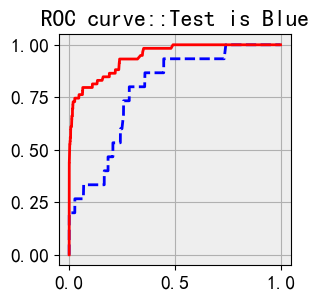

Test AP = 0.1314
Train AP = 0.4942


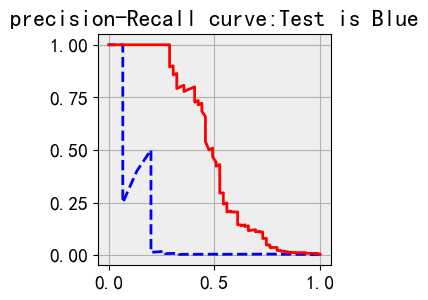

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,3
,learning_rate,np.float64(0.05)
,n_estimators,109
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,np.float64(0.0)
,min_child_weight,0.001
,min_child_samples,20


In [70]:
from sklearn import metrics
#增加空值处理
train_data=train_data.fillna(0)
train_target=train_target.fillna(0)
test_data=test_data.fillna(0)
test_target=test_target.fillna(0)

data={} #原始未进行平衡数据
data['X_train']=train_data 
data['y_train']=train_target 
data['X_test']=test_data
data['y_test']=test_target
trainLGB(data) #进行模型训练